In [11]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED, WINDOW, TARGET = 42,24,"grid_import"
np.random.seed(SEED); tf.random.set_seed(SEED)
print("Tensorflow", tf.__version__)


Tensorflow 2.21.0


In [12]:
CSV = pd.read_csv("smart_building_green_energy_10000.csv")
print(CSV.head())

             timestamp  temperature  humidity  solar_generation  occupancy  \
0  2026-01-01 00:00:00         18.5      78.8               0.0          3   
1  2026-01-01 01:00:00         17.1      83.5               0.0          2   
2  2026-01-01 02:00:00         18.4      72.4               0.0          6   
3  2026-01-01 03:00:00         18.7      76.8               0.0          5   
4  2026-01-01 04:00:00         17.0      83.3               0.0          0   

   building_load  ev_charging_load  battery_soc  grid_import  
0           8.38              0.00         78.0         8.38  
1           7.56              0.00         77.5         7.56  
2           9.11              0.11         76.3         9.22  
3           8.53              0.00         75.7         8.53  
4           7.87              0.00         74.0         7.87  


In [13]:
CSV = "mart_building_green_energy_10000.csv"
if not os.path.exists(CSV):
   CSV  = "smart_building_green_energy_10000.csv"
df = pd.read_csv(CSV, parse_dates = ["timestamp"]).sort_values("timestamp").reset_index(drop=True) 
print(df.shape, "| missing values:" ,int(df.isna().sum().sum()))
print("Range: " ,df["timestamp"].min(), "->", df["timestamp"].max())
df.head()

(10000, 9) | missing values: 0
Range:  2026-01-01 00:00:00 -> 2027-02-21 15:00:00


,timestamp,temperature,humidity,solar_generation,occupancy,building_load,ev_charging_load,battery_soc,grid_import
0,2026-01-01 00:00:00,18.5,78.8,0.0,3,8.38,0.00,78.0,8.38
1,2026-01-01 01:00:00,17.1,83.5,0.0,2,7.56,0.00,77.5,7.56
2,2026-01-01 02:00:00,18.4,72.4,0.0,6,9.11,0.11,76.3,9.22
3,2026-01-01 03:00:00,18.7,76.8,0.0,5,8.53,0.00,75.7,8.53
4,2026-01-01 04:00:00,17.0,83.3,0.0,0,7.87,0.00,74.0,7.87


In [14]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
timestamp,10000,2026-07-28 07:30:00,2026-01-01 00:00:00,2026-04-15 03:45:00,2026-07-28 07:30:00,2026-11-09 11:15:00,2027-02-21 15:00:00,NaN
temperature,10000.0,24.65786,17.0,21.8,24.7,27.2,34.9,3.757948
humidity,10000.0,70.50805,47.3,66.2,70.5,74.9,90.0,6.21784
solar_generation,10000.0,4.300812,0.0,0.0,0.36,9.11,18.23,5.252392
occupancy,10000.0,17.3228,0.0,4.0,7.0,37.0,55.0,17.719328
building_load,10000.0,13.005828,7.5,8.96,10.35,18.57,24.96,5.132652
ev_charging_load,10000.0,0.50503,0.0,0.0,0.02,0.12,4.76,1.034179
battery_soc,10000.0,20.3245,20.0,20.0,20.0,20.0,78.0,2.398837
grid_import,10000.0,9.263743,0.0,7.87,9.18,10.82,24.62,3.715992


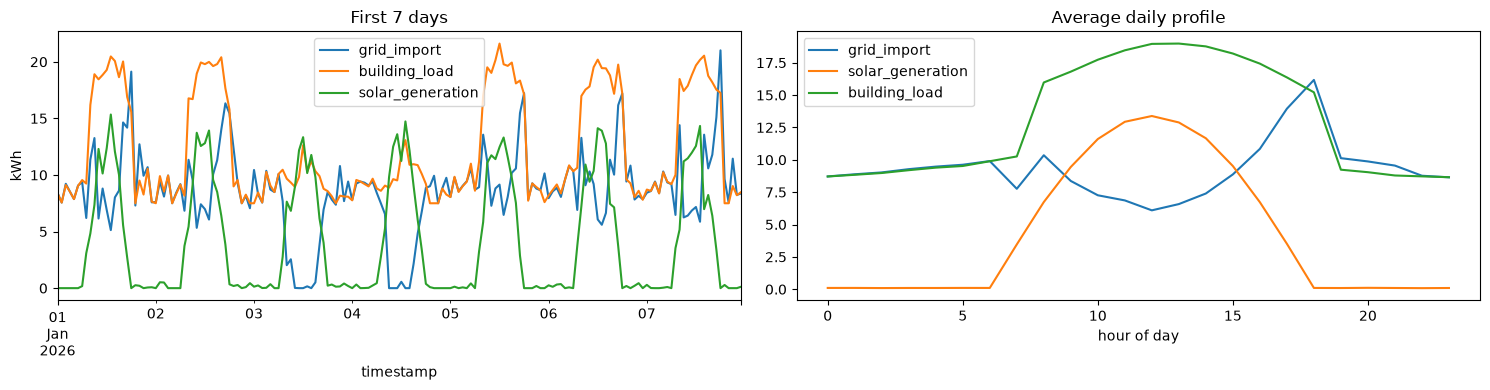

In [15]:
fig,ax = plt.subplots(1, 2, figsize=(15, 4))
df.set_index("timestamp")[["grid_import",  "building_load", "solar_generation"]].iloc[:168].plot(ax=ax[0])
ax[0].set_title("First 7 days"); ax[0].set_ylabel("kWh")
df.groupby(df["timestamp"].dt.hour)[["grid_import", "solar_generation", "building_load"]].mean().plot(ax=ax[1])
ax[1].set_title("Average daily profile"); ax[1].set_xlabel("hour of day")
plt.tight_layout();plt.show()

In [16]:
hour, dow = df["timestamp"].dt.hour, df["timestamp"].dt.dayofweek
df["hour_sin"], df["hour_cos"] = np.sin(2*np.pi*hour/24), np.cos(2*np.pi*hour/24)
df["dow_sin"],  df["dow_cos"]  = np.sin(2*np.pi*dow/7),  np.cos(2*np.pi*dow/7)

features = [c for c in df.columns if c != "timestamp"]   # includes past grid_import (autoregressive input)
print(features)


n = len(df)
i_tr, i_va = int(n*0.70), int(n*0.85)

scaler = MinMaxScaler().fit(df.loc[:i_tr-1, features])
data = scaler.transform(df[features])
t_idx = features.index(TARGET)
t_min, t_max = scaler.data_min_[t_idx], scaler.data_max_[t_idx]
inv = lambda v: v*(t_max - t_min) + t_min               # back to kWh

def make_windows(arr, start, end):
    X, y = [], []
    for t in range(max(start, WINDOW), end):
        X.append(arr[t-WINDOW:t]); y.append(arr[t, t_idx])
    return np.array(X, dtype="float32"), np.array(y, dtype="float32")

Xtr, ytr = make_windows(data, 0, i_tr)
Xva, yva = make_windows(data, i_tr, i_va)
Xte, yte = make_windows(data, i_va, n)
print("train", Xtr.shape, "| val", Xva.shape, "| test", Xte.shape)


def build(kind):
    cell = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM}[kind]
    m = models.Sequential([
        layers.Input(shape=(WINDOW, len(features))),
        cell(64, return_sequences=True),
        layers.Dropout(0.2),
        cell(32),
        layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dense(1),
    ], name=kind)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return m

build("RNN").summary()
build("LSTM").summary()

['temperature', 'humidity', 'solar_generation', 'occupancy', 'building_load', 'ev_charging_load', 'battery_soc', 'grid_import', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos']
train (6976, 24, 12) | val (1500, 24, 12) | test (1500, 24, 12)


Model: "RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 24, 64)         │         4,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,577 (33.50 KB)

 Trainable params: 8,577 (33.50 KB)

...

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,673 (127.63 KB)

 Trainable params: 32,673 (127.63 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

results, histories, preds, trained = {}, {}, {}, {}
y_true = inv(yte)
results["Persistence (baseline)"] = metrics(y_true, inv(Xte[:, -1, t_idx]))   # next hour = this hour

for kind in ["RNN", "LSTM"]:
    print(f"=== Training {kind} ===")
    model = build(kind)
    cbs = [callbacks.EarlyStopping(patience=8, restore_best_weights=True, monitor="val_loss"),
           callbacks.ReduceLROnPlateau(patience=3, factor=0.5, min_lr=1e-5)]
    h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=60, batch_size=64,
                  callbacks=cbs, verbose=0)
    print(f"stopped after {len(h.history['loss'])} epochs, best val_loss = {min(h.history['val_loss']):.5f}")
    p = inv(model.predict(Xte, verbose=0).ravel())
    results[kind], histories[kind], preds[kind], trained[kind] = metrics(y_true, p), h.history, p, model

=== Training RNN ===
stopped after 34 epochs, best val_loss = 0.00427
=== Training LSTM ===
stopped after 41 epochs, best val_loss = 0.00405


In [19]:
res = pd.DataFrame(results).T.round(4)
res

,MAE,RMSE,R2
Persistence (baseline),2.0838,2.9785,0.3169
RNN,1.2922,1.7034,0.7766
LSTM,1.1999,1.6413,0.7926


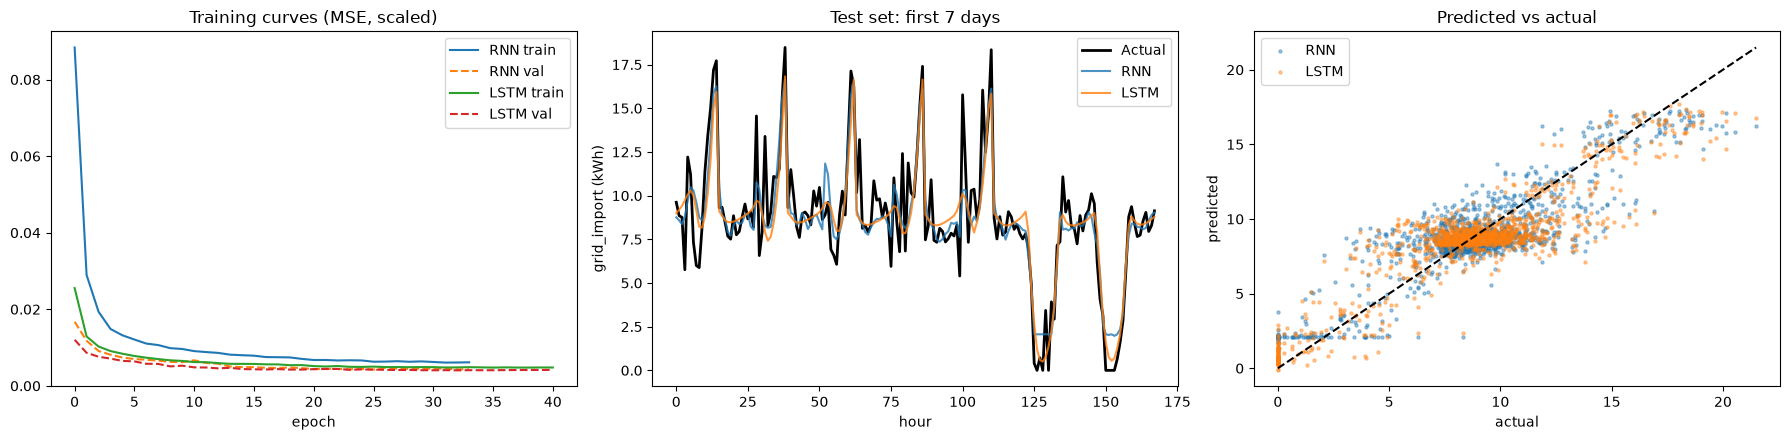

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for k, h in histories.items():
    ax[0].plot(h["loss"], label=f"{k} train"); ax[0].plot(h["val_loss"], "--", label=f"{k} val")
ax[0].set(title="Training curves (MSE, scaled)", xlabel="epoch"); ax[0].legend()

seg = slice(0, 168)
ax[1].plot(y_true[seg], "k", lw=2, label="Actual")
for k, p in preds.items(): ax[1].plot(p[seg], alpha=.8, label=k)
ax[1].set(title="Test set: first 7 days", xlabel="hour", ylabel="grid_import (kWh)"); ax[1].legend()

ax[2].scatter(y_true, preds["RNN"],  s=5, alpha=.4, label="RNN")
ax[2].scatter(y_true, preds["LSTM"], s=5, alpha=.4, label="LSTM")
lim = [0, y_true.max()]; ax[2].plot(lim, lim, "k--")
ax[2].set(title="Predicted vs actual", xlabel="actual", ylabel="predicted"); ax[2].legend()
plt.tight_layout(); plt.show()

In [ ]:
import cv2
image = cv2.imread("C:/Users/vigne/Downloads/white rose.jpg" , cv2.IMREAD_COLOR)
if image is None:
    print("Error: Image not found or unable to load.")
else:
    print("Image loaded successfully!")    


Image loaded successfully!


In [1]:
import cv2

img = cv2.imread("C:/Users/vigne/Downloads/white rose.jpg")

cv2.imshow("Original Image", img)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [2]:
import cv2

img = cv2.imread("C:/Users/vigne/Downloads/white rose.jpg")

print("Height:", img.shape[0])
print("Width:", img.shape[1])
print("Channels:", img.shape[2])

Height: 447
Width: 447
Channels: 3


In [3]:
import cv2

img = cv2.imread("C:/Users/vigne/Downloads/white rose.jpg")

resized = cv2.resize(img, (500, 400))

cv2.imshow("Resized Image", resized)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [4]:
import cv2

img = cv2.imread("C:/Users/vigne/Downloads/white rose.jpg")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

cv2.imshow("Grayscale Image", gray)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [5]:
import cv2

img = cv2.imread("C:/Users/vigne/Downloads/white rose.jpg")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

cv2.imwrite("gray_image.jpg", gray)

print("Image saved successfully")

Image saved successfully


In [7]:
import cv2

img = cv2.imread("C:/Users/vigne/Downloads/white rose.jpg")

blur = cv2.GaussianBlur(img, (5, 5), 0)

cv2.imshow("Blurred Image", blur)
cv2.waitKey(0)
cv2.destroyAllWindows()